In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../Data/german_credit_data.csv")

In [69]:
df.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


In [70]:
df.shape

(1000, 11)

In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Sex               1000 non-null   object
 3   Job               1000 non-null   int64 
 4   Housing           1000 non-null   object
 5   Saving accounts   817 non-null    object
 6   Checking account  606 non-null    object
 7   Credit amount     1000 non-null   int64 
 8   Duration          1000 non-null   int64 
 9   Purpose           1000 non-null   object
 10  Risk              1000 non-null   object
dtypes: int64(5), object(6)
memory usage: 86.1+ KB


In [72]:
df.isnull().sum()

Unnamed: 0            0
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

In [73]:
df.duplicated().sum()

np.int64(0)

In [74]:
df["Risk"].value_counts()

Risk
good    700
bad     300
Name: count, dtype: int64

In [75]:
df["Risk"].value_counts(normalize=True) * 100

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64

In [76]:
df.describe()

,Unnamed: 0,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,35.546000,1.904000,3271.258000,20.903000
std,288.819436,11.375469,0.653614,2822.736876,12.058814
min,0.000000,19.000000,0.000000,250.000000,4.000000
25%,249.750000,27.000000,2.000000,1365.500000,12.000000
50%,499.500000,33.000000,2.000000,2319.500000,18.000000
75%,749.250000,42.000000,2.000000,3972.250000,24.000000
max,999.000000,75.000000,3.000000,18424.000000,72.000000


In [77]:
for column in df.select_dtypes(include="object").columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


Sex
Sex
male      690
female    310
Name: count, dtype: int64

Housing
Housing
own     713
rent    179
free    108
Name: count, dtype: int64

Saving accounts
Saving accounts
little        603
NaN           183
moderate      103
quite rich     63
rich           48
Name: count, dtype: int64

Checking account
Checking account
NaN         394
little      274
moderate    269
rich         63
Name: count, dtype: int64

Purpose
Purpose
car                    337
radio/TV               280
furniture/equipment    181
business                97
education               59
repairs                 22
domestic appliances     12
vacation/others         12
Name: count, dtype: int64

Risk
Risk
good    700
bad     300
Name: count, dtype: int64


In [78]:
df["Unnamed: 0"].head(10)

0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: Unnamed: 0, dtype: int64

In [79]:
df["Unnamed: 0"].nunique()

1000

In [80]:
df = df.drop(columns=["Unnamed: 0"])

In [81]:
df.shape

(1000, 10)

In [82]:
df.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account',
       'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='object')

In [83]:
df.duplicated().sum()

np.int64(0)

In [84]:
target = "Risk"

df[target].value_counts()

Risk
good    700
bad     300
Name: count, dtype: int64

In [85]:
df[target].value_counts(normalize=True).mul(100).round(2)

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64

In [86]:
X = df.drop(columns=["Risk"])
y = df["Risk"]

In [87]:
X.shape

(1000, 9)

In [88]:
y.shape

(1000,)

In [89]:
y.unique()

array(['good', 'bad'], dtype=object)

In [90]:
from sklearn.model_selection import train_test_split

In [91]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [92]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (800, 9)
X_test : (200, 9)
y_train: (800,)
y_test : (200,)


In [93]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training target distribution:
Risk
good    0.7
bad     0.3
Name: proportion, dtype: float64

Testing target distribution:
Risk
good    0.7
bad     0.3
Name: proportion, dtype: float64


In [94]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [95]:
numerical_features = [
    "Age",
    "Job",
    "Credit amount",
    "Duration"
]

categorical_features = [
    "Sex",
    "Housing",
    "Saving accounts",
    "Checking account",
    "Purpose"
]

In [96]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [97]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [98]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [99]:
print("X_train_processed:", X_train_processed.shape)
print("X_test_processed :", X_test_processed.shape)

X_train_processed: (800, 24)
X_test_processed : (200, 24)


In [100]:
from sklearn.linear_model import LogisticRegression

In [101]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [102]:
logistic_model.fit(X_train_processed, y_train)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=42)

In [103]:
y_pred_logistic = logistic_model.predict(X_test_processed)

In [104]:
logistic_model.classes_

array(['bad', 'good'], dtype=object)

In [105]:
bad_class_index = list(logistic_model.classes_).index("bad")

y_prob_bad = logistic_model.predict_proba(
    X_test_processed
)[:, bad_class_index]

In [106]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [107]:
print("Accuracy :", accuracy_score(y_test, y_pred_logistic))
print("Precision:", precision_score(y_test, y_pred_logistic, pos_label="bad"))
print("Recall   :", recall_score(y_test, y_pred_logistic, pos_label="bad"))
print("F1-score :", f1_score(y_test, y_pred_logistic, pos_label="bad"))
print("ROC-AUC  :", roc_auc_score(
    (y_test == "bad").astype(int),
    y_prob_bad
))

Accuracy : 0.705
Precision: 0.5172413793103449
Recall   : 0.25
F1-score : 0.33707865168539325
ROC-AUC  : 0.66


In [108]:
print(classification_report(y_test, y_pred_logistic))

              precision    recall  f1-score   support

         bad       0.52      0.25      0.34        60
        good       0.74      0.90      0.81       140

    accuracy                           0.70       200
   macro avg       0.63      0.57      0.57       200
weighted avg       0.67      0.70      0.67       200



In [109]:
cm = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=["bad", "good"]
)

cm

array([[ 15,  45],
       [ 14, 126]])

In [110]:
from sklearn.tree import DecisionTreeClassifier
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5,
    min_samples_leaf=10
)
decision_tree.fit(X_train_processed, y_train)
y_pred_tree = decision_tree.predict(X_test_processed)

In [111]:
decision_tree.classes_

array(['bad', 'good'], dtype=object)

In [112]:
bad_class_index_tree = list(
    decision_tree.classes_
).index("bad")

y_prob_bad_tree = decision_tree.predict_proba(
    X_test_processed
)[:, bad_class_index_tree]

In [113]:
print("Decision Tree Results")
print("---------------------")

print("Accuracy :",
      accuracy_score(y_test, y_pred_tree))

print("Precision:",
      precision_score(y_test, y_pred_tree, pos_label="bad"))

print("Recall   :",
      recall_score(y_test, y_pred_tree, pos_label="bad"))

print("F1-score :",
      f1_score(y_test, y_pred_tree, pos_label="bad"))

print("ROC-AUC  :",
      roc_auc_score(
          (y_test == "bad").astype(int),
          y_prob_bad_tree
      ))

Decision Tree Results
---------------------
Accuracy : 0.69
Precision: 0.4722222222222222
Recall   : 0.2833333333333333
F1-score : 0.3541666666666667
ROC-AUC  : 0.6373809523809524


In [114]:
print(
    classification_report(
        y_test,
        y_pred_tree
    )
)

              precision    recall  f1-score   support

         bad       0.47      0.28      0.35        60
        good       0.74      0.86      0.80       140

    accuracy                           0.69       200
   macro avg       0.61      0.57      0.58       200
weighted avg       0.66      0.69      0.66       200



In [115]:
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=["bad", "good"]
)

cm_tree

array([[ 17,  43],
       [ 19, 121]])

In [116]:
from sklearn.ensemble import RandomForestClassifier
random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
random_forest.fit(X_train_processed, y_train)
y_pred_rf = random_forest.predict(X_test_processed)
random_forest.classes_

array(['bad', 'good'], dtype=object)

In [117]:
bad_class_index_rf = list(
    random_forest.classes_
).index("bad")

y_prob_bad_rf = random_forest.predict_proba(
    X_test_processed
)[:, bad_class_index_rf]

In [118]:
print("Random Forest Results")
print("---------------------")

print("Accuracy :",
      accuracy_score(y_test, y_pred_rf))

print("Precision:",
      precision_score(y_test, y_pred_rf, pos_label="bad"))

print("Recall   :",
      recall_score(y_test, y_pred_rf, pos_label="bad"))

print("F1-score :",
      f1_score(y_test, y_pred_rf, pos_label="bad"))

print("ROC-AUC  :",
      roc_auc_score(
          (y_test == "bad").astype(int),
          y_prob_bad_rf
      ))

Random Forest Results
---------------------
Accuracy : 0.71
Precision: 0.5625
Recall   : 0.15
F1-score : 0.23684210526315788
ROC-AUC  : 0.6642857142857144


In [119]:
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

              precision    recall  f1-score   support

         bad       0.56      0.15      0.24        60
        good       0.72      0.95      0.82       140

    accuracy                           0.71       200
   macro avg       0.64      0.55      0.53       200
weighted avg       0.67      0.71      0.65       200



In [120]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=["bad", "good"]
)

cm_rf

array([[  9,  51],
       [  7, 133]])

In [121]:
from sklearn.ensemble import ExtraTreesClassifier

In [122]:
extra_trees = ExtraTreesClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

In [123]:
extra_trees.fit(X_train_processed, y_train)

ExtraTreesClassifier(max_depth=8, min_samples_leaf=5, n_estimators=300,
                     n_jobs=-1, random_state=42)

In [124]:
y_pred_et = extra_trees.predict(X_test_processed)

In [125]:
extra_trees.classes_

array(['bad', 'good'], dtype=object)

In [126]:
bad_class_index_et = list(
    extra_trees.classes_
).index("bad")

y_prob_bad_et = extra_trees.predict_proba(
    X_test_processed
)[:, bad_class_index_et]

In [127]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Extra Trees"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_et)
    ],
    "BAD Precision": [
        precision_score(y_test, y_pred_logistic, pos_label="bad"),
        precision_score(y_test, y_pred_tree, pos_label="bad"),
        precision_score(y_test, y_pred_rf, pos_label="bad"),
        precision_score(y_test, y_pred_et, pos_label="bad")
    ],
    "BAD Recall": [
        recall_score(y_test, y_pred_logistic, pos_label="bad"),
        recall_score(y_test, y_pred_tree, pos_label="bad"),
        recall_score(y_test, y_pred_rf, pos_label="bad"),
        recall_score(y_test, y_pred_et, pos_label="bad")
    ],
    "BAD F1": [
        f1_score(y_test, y_pred_logistic, pos_label="bad"),
        f1_score(y_test, y_pred_tree, pos_label="bad"),
        f1_score(y_test, y_pred_rf, pos_label="bad"),
        f1_score(y_test, y_pred_et, pos_label="bad")
    ],
    "ROC-AUC": [
        roc_auc_score((y_test == "bad").astype(int), y_prob_bad),
        roc_auc_score((y_test == "bad").astype(int), y_prob_bad_tree),
        roc_auc_score((y_test == "bad").astype(int), y_prob_bad_rf),
        roc_auc_score((y_test == "bad").astype(int), y_prob_bad_et)
    ]
})

model_results.round(3)

,Model,Accuracy,BAD Precision,BAD Recall,BAD F1,ROC-AUC
0,Logistic Regression,0.705,0.517,0.250,0.337,0.660
1,Decision Tree,0.690,0.472,0.283,0.354,0.637
2,Random Forest,0.710,0.562,0.150,0.237,0.664
3,Extra Trees,0.705,0.529,0.150,0.234,0.628


In [128]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [129]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [130]:
cv_logistic = cross_val_score(
    logistic_model,
    X_train_processed,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("Logistic Regression CV ROC-AUC:")
print(cv_logistic)
print("Mean:", cv_logistic.mean())
print("Std :", cv_logistic.std())

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_

Logistic Regression CV ROC-AUC:
[0.6906622  0.77157738 0.56417411 0.67633929 0.60528274]
Mean: 0.6616071428571428
Std : 0.0718614233147423


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [131]:
cv_tree = cross_val_score(
    decision_tree,
    X_train_processed,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("Decision Tree CV ROC-AUC:")
print(cv_tree)
print("Mean:", cv_tree.mean())
print("Std :", cv_tree.std())

Decision Tree CV ROC-AUC:
[0.74079241 0.66145833 0.53776042 0.62007068 0.61393229]
Mean: 0.6348028273809523
Std : 0.0663538281399886


In [132]:
cv_rf = cross_val_score(
    random_forest,
    X_train_processed,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("Random Forest CV ROC-AUC:")
print(cv_rf)
print("Mean:", cv_rf.mean())
print("Std :", cv_rf.std())

Random Forest CV ROC-AUC:
[0.67950149 0.75241815 0.54817708 0.7046131  0.62946429]
Mean: 0.6628348214285715
Std : 0.06972569843374399


In [133]:
cv_et = cross_val_score(
    extra_trees,
    X_train_processed,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("Extra Trees CV ROC-AUC:")
print(cv_et)
print("Mean:", cv_et.mean())
print("Std :", cv_et.std())

Extra Trees CV ROC-AUC:
[0.61904762 0.75297619 0.55859375 0.70982143 0.58035714]
Mean: 0.6441592261904762
Std : 0.075067177787032


In [134]:
cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Extra Trees"
    ],
    "Mean CV ROC-AUC": [
        cv_logistic.mean(),
        cv_tree.mean(),
        cv_rf.mean(),
        cv_et.mean()
    ],
    "CV ROC-AUC Std": [
        cv_logistic.std(),
        cv_tree.std(),
        cv_rf.std(),
        cv_et.std()
    ]
})

cv_results.round(3)

,Model,Mean CV ROC-AUC,CV ROC-AUC Std
0,Logistic Regression,0.662,0.072
1,Decision Tree,0.635,0.066
2,Random Forest,0.663,0.070
3,Extra Trees,0.644,0.075


In [135]:
model_results.round(3)

,Model,Accuracy,BAD Precision,BAD Recall,BAD F1,ROC-AUC
0,Logistic Regression,0.705,0.517,0.250,0.337,0.660
1,Decision Tree,0.690,0.472,0.283,0.354,0.637
2,Random Forest,0.710,0.562,0.150,0.237,0.664
3,Extra Trees,0.705,0.529,0.150,0.234,0.628


In [136]:
cv_results.round(3)

,Model,Mean CV ROC-AUC,CV ROC-AUC Std
0,Logistic Regression,0.662,0.072
1,Decision Tree,0.635,0.066
2,Random Forest,0.663,0.070
3,Extra Trees,0.644,0.075


In [137]:
from sklearn.model_selection import GridSearchCV

In [138]:
rf_param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [5, 8, 12, None],
    "min_samples_leaf": [2, 5, 10],
    "max_features": ["sqrt", "log2"]
}

In [139]:
rf_grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=rf_param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

In [140]:
rf_grid_search.fit(
    X_train_processed,
    y_train
)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [5, 8, 12, None],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [2, 5, 10],
                         'n_estimators': [200, 300, 500]},
             scoring='roc_auc', verbose=1)

In [141]:
print("Best parameters:")
print(rf_grid_search.best_params_)

Best parameters:
{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 500}


In [142]:
print("Best CV ROC-AUC:")
print(rf_grid_search.best_score_)

Best CV ROC-AUC:
0.6677827380952381


In [143]:
best_rf = rf_grid_search.best_estimator_

In [144]:
y_pred_rf_tuned = best_rf.predict(X_test_processed)

In [145]:
bad_class_index_rf_tuned = list(
    best_rf.classes_
).index("bad")

y_prob_bad_rf_tuned = best_rf.predict_proba(
    X_test_processed
)[:, bad_class_index_rf_tuned]

In [146]:
print("Tuned Random Forest Results")
print("---------------------------")

print("Accuracy :",
      accuracy_score(y_test, y_pred_rf_tuned))

print("BAD Precision:",
      precision_score(
          y_test,
          y_pred_rf_tuned,
          pos_label="bad"
      ))

print("BAD Recall:",
      recall_score(
          y_test,
          y_pred_rf_tuned,
          pos_label="bad"
      ))

print("BAD F1:",
      f1_score(
          y_test,
          y_pred_rf_tuned,
          pos_label="bad"
      ))

print("ROC-AUC:",
      roc_auc_score(
          (y_test == "bad").astype(int),
          y_prob_bad_rf_tuned
      ))

Tuned Random Forest Results
---------------------------
Accuracy : 0.715
BAD Precision: 0.5882352941176471
BAD Recall: 0.16666666666666666
BAD F1: 0.2597402597402597
ROC-AUC: 0.6657142857142857


In [150]:
y_pred_rf_tuned = best_rf.predict(X_test_processed)

In [151]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.20, 0.61, 0.05)

threshold_results = []

for threshold in thresholds:
    
    y_pred_threshold = np.where(
        y_prob_bad_rf_tuned >= threshold,
        "bad",
        "good"
    )
    
    threshold_results.append({
        "Threshold": threshold,
        "BAD Precision": precision_score(
            y_test,
            y_pred_threshold,
            pos_label="bad",
            zero_division=0
        ),
        "BAD Recall": recall_score(
            y_test,
            y_pred_threshold,
            pos_label="bad",
            zero_division=0
        ),
        "BAD F1": f1_score(
            y_test,
            y_pred_threshold,
            pos_label="bad",
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results.round(3)

,Threshold,BAD Precision,BAD Recall,BAD F1
0,0.20,0.320,0.900,0.472
1,0.25,0.395,0.817,0.533
2,0.30,0.388,0.550,0.455
3,0.35,0.443,0.450,0.446
4,0.40,0.457,0.350,0.396
5,0.45,0.548,0.283,0.374
6,0.50,0.588,0.167,0.260
7,0.55,0.667,0.100,0.174
8,0.60,1.000,0.017,0.033


In [152]:
best_threshold_row = threshold_results.loc[
    threshold_results["BAD F1"].idxmax()
]

best_threshold_row

Threshold        0.250000
BAD Precision    0.395161
BAD Recall       0.816667
BAD F1           0.532609
Name: 1, dtype: float64

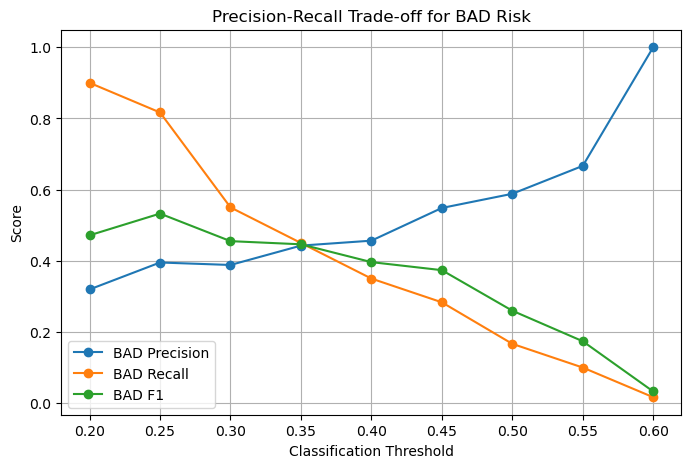

In [153]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["BAD Precision"],
    marker="o",
    label="BAD Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["BAD Recall"],
    marker="o",
    label="BAD Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["BAD F1"],
    marker="o",
    label="BAD F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall Trade-off for BAD Risk")
plt.legend()
plt.grid(True)
plt.show()

In [154]:
from sklearn.model_selection import cross_val_predict

In [155]:
cv_prob_bad_rf = cross_val_predict(
    best_rf,
    X_train_processed,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

In [156]:
bad_class_index_cv = list(
    best_rf.classes_
).index("bad")

cv_prob_bad = cv_prob_bad_rf[:, bad_class_index_cv]

In [157]:
thresholds = np.arange(0.20, 0.61, 0.05)

cv_threshold_results = []

for threshold in thresholds:
    
    y_pred_cv = np.where(
        cv_prob_bad >= threshold,
        "bad",
        "good"
    )
    
    cv_threshold_results.append({
        "Threshold": threshold,
        "BAD Precision": precision_score(
            y_train,
            y_pred_cv,
            pos_label="bad",
            zero_division=0
        ),
        "BAD Recall": recall_score(
            y_train,
            y_pred_cv,
            pos_label="bad",
            zero_division=0
        ),
        "BAD F1": f1_score(
            y_train,
            y_pred_cv,
            pos_label="bad",
            zero_division=0
        )
    })

cv_threshold_results = pd.DataFrame(
    cv_threshold_results
)

cv_threshold_results.round(3)

,Threshold,BAD Precision,BAD Recall,BAD F1
0,0.20,0.333,0.908,0.487
1,0.25,0.370,0.783,0.503
2,0.30,0.406,0.621,0.491
3,0.35,0.431,0.446,0.439
4,0.40,0.504,0.292,0.369
5,0.45,0.560,0.196,0.290
6,0.50,0.636,0.088,0.154
7,0.55,0.647,0.046,0.086
8,0.60,0.714,0.021,0.040


In [158]:
best_cv_threshold_row = cv_threshold_results.loc[
    cv_threshold_results["BAD F1"].idxmax()
]

best_cv_threshold_row

Threshold        0.250000
BAD Precision    0.370079
BAD Recall       0.783333
BAD F1           0.502674
Name: 1, dtype: float64

In [160]:
best_cv_threshold = best_cv_threshold_row["Threshold"]

In [161]:
y_pred_rf_final = np.where(
    y_prob_bad_rf_tuned >= best_cv_threshold,
    "bad",
    "good"
)

In [162]:
y_pred_rf_final = np.where(
    y_prob_bad_rf_tuned >= best_cv_threshold,
    "bad",
    "good"
)

In [163]:
cm_rf_final = confusion_matrix(
    y_test,
    y_pred_rf_final,
    labels=["bad", "good"]
)

cm_rf_final

array([[49, 11],
       [75, 65]])

In [164]:
from sklearn.metrics import precision_recall_curve, average_precision_score

In [165]:
y_test_binary = (y_test == "bad").astype(int)

precision, recall, pr_thresholds = precision_recall_curve(
    y_test_binary,
    y_prob_bad_rf_tuned
)

In [166]:
average_precision = average_precision_score(
    y_test_binary,
    y_prob_bad_rf_tuned
)

print("Average Precision:", average_precision)

Average Precision: 0.46060510153429995


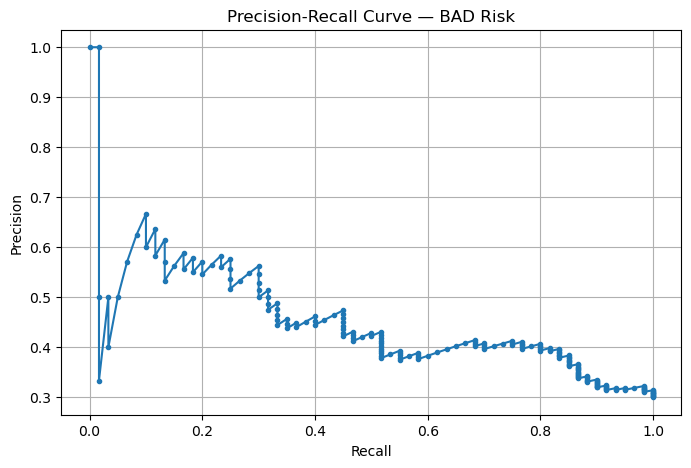

In [167]:
plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    marker="."
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — BAD Risk")

plt.grid(True)
plt.show()

In [168]:
feature_names = preprocessor.get_feature_names_out()

len(feature_names)

24

In [169]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
2,num__Credit amount,0.230822
3,num__Duration,0.206438
0,num__Age,0.158303
21,cat__Purpose_radio/TV,0.045477
14,cat__Checking account_moderate,0.039294
1,num__Job,0.037184
7,cat__Housing_own,0.034404
9,cat__Saving accounts_little,0.029440
13,cat__Checking account_little,0.028923
17,cat__Purpose_car,0.028415


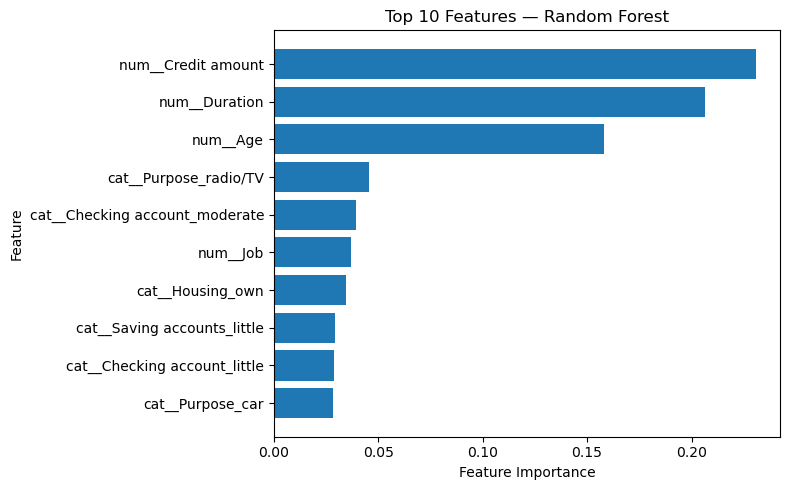

In [170]:
top_features = feature_importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(8, 5))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features — Random Forest")

plt.tight_layout()
plt.show()

In [171]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "BAD Precision",
        "BAD Recall",
        "BAD F1",
        "ROC-AUC",
        "Average Precision"
    ],
    "Score": [
        accuracy_score(y_test, y_pred_rf_final),
        precision_score(
            y_test,
            y_pred_rf_final,
            pos_label="bad",
            zero_division=0
        ),
        recall_score(
            y_test,
            y_pred_rf_final,
            pos_label="bad",
            zero_division=0
        ),
        f1_score(
            y_test,
            y_pred_rf_final,
            pos_label="bad",
            zero_division=0
        ),
        roc_auc_score(
            y_test_binary,
            y_prob_bad_rf_tuned
        ),
        average_precision
    ]
})

final_results.round(3)

,Metric,Score
0,Accuracy,0.570
1,BAD Precision,0.395
2,BAD Recall,0.817
3,BAD F1,0.533
4,ROC-AUC,0.666
5,Average Precision,0.461


In [172]:
cm_rf_final

array([[49, 11],
       [75, 65]])

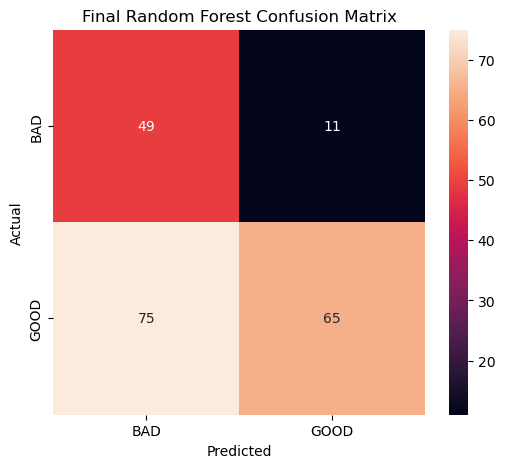

In [173]:
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf_final,
    annot=True,
    fmt="d",
    xticklabels=["BAD", "GOOD"],
    yticklabels=["BAD", "GOOD"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Random Forest Confusion Matrix")

plt.show()

In [174]:
from sklearn.pipeline import Pipeline

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_rf)
])

In [175]:
pipeline_pred = final_model.predict(X_test)

print("Pipeline predictions:")
print(pipeline_pred[:10])

Pipeline predictions:
['good' 'good' 'bad' 'good' 'good' 'good' 'good' 'good' 'good' 'good']


In [176]:
pipeline_prob = final_model.predict_proba(X_test)

print("Probability shape:", pipeline_prob.shape)
print("First 5 probabilities:")
print(pipeline_prob[:5])

Probability shape: (200, 2)
First 5 probabilities:
[[0.25934286 0.74065714]
 [0.4976521  0.5023479 ]
 [0.58463238 0.41536762]
 [0.16238684 0.83761316]
 [0.48300572 0.51699428]]


In [177]:
from sklearn.metrics import accuracy_score, roc_auc_score

pipeline_accuracy = accuracy_score(y_test, pipeline_pred)

bad_index = list(final_model.classes_).index("bad")

pipeline_prob_bad = pipeline_prob[:, bad_index]

y_test_binary = (y_test == "bad").astype(int)

pipeline_roc_auc = roc_auc_score(
    y_test_binary,
    pipeline_prob_bad
)

print("Pipeline Accuracy:", round(pipeline_accuracy, 3))
print("Pipeline ROC-AUC:", round(pipeline_roc_auc, 3))

Pipeline Accuracy: 0.715
Pipeline ROC-AUC: 0.666


In [178]:
import joblib

joblib.dump(
    final_model,
    "../models/credit_risk_pipeline.pkl"
)

['../models/credit_risk_pipeline.pkl']